
# Post-processing: plot and analyze the results

In [1]:
import glob, os
import meshio

import numpy as np
import math

import matplotlib.pyplot as plt
from matplotlib import mathtext
from scipy import stats 

In [2]:
# Plot parameters
params = {
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "font.size": 12,
    "legend.fontsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "text.usetex": False,
    "figure.figsize": (9, 6.45),
    "figure.subplot.left": 0.045,
    "figure.subplot.right": 0.99,
    "figure.subplot.bottom": 0.05,
    "figure.subplot.top": 0.99,
    "figure.subplot.wspace": 0.15,
    "figure.subplot.hspace": 0.12,
    "lines.markersize": 6,
    "lines.linewidth": 3.0,
}
plt.rcParams.update(params)
plt.rc('font', family='serif')
#plt.rc('text', usetex=False)

## Read simulation data

In [138]:
from tkinter import Tcl

# Import snapshots
snapshot_number = 200
#snapshot_dir = ''
#snapshot_dir = 'Npart_63_dt_1e-3/'
snapshot_dir = 'Npart_63/'
files = glob.glob(snapshot_dir + "particles*.vtu")
# Sort the snapshots according to Natural sort
files = Tcl().call('lsort', '-dict', files)

# Simulation parameters
time_step_sim = 1e-4
snapshot_rate = 10
time = snapshot_number*snapshot_rate*time_step_sim
N_parts = 63
neighbours = 4.28
eta = 1.235
kernel = 'Cubic Spline (M4)'
scheme = 'Minimal SPH'

snapshot = files[snapshot_number]
print('Reading snapshot: ' + snapshot )
print("time of simulation = ", time)
print("********************************************")

mesh = meshio.read( snapshot )
print(mesh.point_data_to_sets)
print("********************************************")

# Extract Fields
pos = mesh.point_data["x"]
x = pos[:,0] - 0.5
y = pos[:,1] - 0.5
vel = mesh.point_data["v"]
vel_x   = vel[:,0] 
vel_y   = vel[:,1] 
r = np.sqrt(x**2 + y**2)
v_r = (x*vel_x + y*vel_y)/r
density = mesh.point_data["density"][:,0]
pressure= mesh.point_data["pressure"][:,0]
mass    = mesh.point_data["mass"][:,0]
energy  = mesh.point_data["u"][:,0]
Omega   = mesh.point_data["Omega"][:,0]

print("Measure energy conservation:")
E_ini = 0.5000007
E_kin = mass[0] * np.sum( 0.5 * (vel_x**2 + vel_y**2) )
E_int = mass[0] * np.sum(energy)
E_tot = E_kin + E_int
E_dif = (E_tot - E_ini)/E_ini
print("Initial E=", E_ini, "Total E= ", E_tot, "Kinetic E=", E_kin, "Internal E=", E_int)
print("Relative Energy difference = ", E_dif )
print("********************************************")

Reading snapshot: Npart_63/particles-200.vtu
time of simulation =  0.2
********************************************
<bound method Mesh.point_data_to_sets of <meshio mesh object>
  Number of points: 3969
  Number of cells:
    vertex: 3969
  Point data: x, cut-off-radius, association, v, a, a_prev_step, u, mass, density, pressure, f, Omega, rho_dh, Ncount, wcount, wcount_dh, soundSpeed, timeStepSize, smoothingLength, smoothingLengthPrevious, hDot, residual, hasConverged, iterCount, hLeft, hRight, isBoundaryParticle, hasNoNeighbours, rot_v, div_v, v_sig_AV, balsara>
********************************************
Measure energy conservation:
Initial E= 0.5000007 Total E=  0.49340752 Kinetic E= 0.37679404 Internal E= 0.116613485
Relative Energy difference =  -0.01318634619594509
********************************************


In [139]:
# Bin the data
rho = density
P = pressure
v = - np.sqrt(vel_x ** 2 + vel_y ** 2)
u = energy

r_bin_edge = np.arange(0.0, 1.0, 0.02)
r_bin = 0.5 * (r_bin_edge[1:] + r_bin_edge[:-1])
rho_bin, _, _ = stats.binned_statistic(r, rho, statistic="mean", bins=r_bin_edge)
v_bin, _, _ = stats.binned_statistic(r, v, statistic="mean", bins=r_bin_edge)
P_bin, _, _ = stats.binned_statistic(r, P, statistic="mean", bins=r_bin_edge)
u_bin, _, _ = stats.binned_statistic(r, u, statistic="mean", bins=r_bin_edge)
rho2_bin, _, _ = stats.binned_statistic(r, rho ** 2, statistic="mean", bins=r_bin_edge)
v2_bin, _, _ = stats.binned_statistic(r, v ** 2, statistic="mean", bins=r_bin_edge)
P2_bin, _, _ = stats.binned_statistic(r, P ** 2, statistic="mean", bins=r_bin_edge)
u2_bin, _, _ = stats.binned_statistic(r, u ** 2, statistic="mean", bins=r_bin_edge)
rho_sigma_bin = np.sqrt(rho2_bin - rho_bin ** 2)
v_sigma_bin = np.sqrt(v2_bin - v_bin ** 2)
P_sigma_bin = np.sqrt(P2_bin - P_bin ** 2)
u_sigma_bin = np.sqrt(u2_bin - u_bin ** 2)

/tmp/ipykernel_113764/3722062577.py:17: RuntimeWarning: invalid value encountered in sqrt
  rho_sigma_bin = np.sqrt(rho2_bin - rho_bin ** 2)
/tmp/ipykernel_113764/3722062577.py:18: RuntimeWarning: invalid value encountered in sqrt
  v_sigma_bin = np.sqrt(v2_bin - v_bin ** 2)
/tmp/ipykernel_113764/3722062577.py:19: RuntimeWarning: invalid value encountered in sqrt
  P_sigma_bin = np.sqrt(P2_bin - P_bin ** 2)


## Analytical solution

Taken from `swiftsim/examples/HydroTests/Noh_2D`

In [140]:
# Parameters
rho0 = 1.0                     # Background Density
v0 = 1                         # Magnitude of the initial velocity
P0 = 6.6e-7                    # Background Pressure
u0 = 1e-6                      # Background internal energy
gas_gamma = 5.0/3.0            # Gas polytropic index

N = 1000  # Number of points

x_s = np.arange(0, 2.0, 2.0 / N) - 1.0
rho_s = np.ones(N) * rho0
P_s = np.ones(N) * rho0
v_s = np.ones(N) * v0

# Shock position
u0 = rho0 * P0 * (gas_gamma - 1)
us = 0.5 * (gas_gamma - 1) * v0
rs = us * time

# Post-shock values
rho_s[np.abs(x_s) < rs] = rho0 * ((gas_gamma + 1) / (gas_gamma - 1)) ** 2
P_s[np.abs(x_s) < rs] = 0.5 * rho0 * v0 ** 2 * (gas_gamma + 1) ** 2 / (gas_gamma - 1)
v_s[np.abs(x_s) < rs] = 0.0

# Pre-shock values
rho_s[np.abs(x_s) >= rs] = rho0 * (1 + v0 * time / np.abs(x_s[np.abs(x_s) >= rs]))
P_s[np.abs(x_s) >= rs] = 0
v_s[x_s >= rs] = -v0
v_s[x_s <= -rs] = v0

# Additional arrays
u_s = P_s / (rho_s * (gas_gamma - 1.0))  # internal energy
s_s = P_s / rho_s ** gas_gamma  # entropic function  

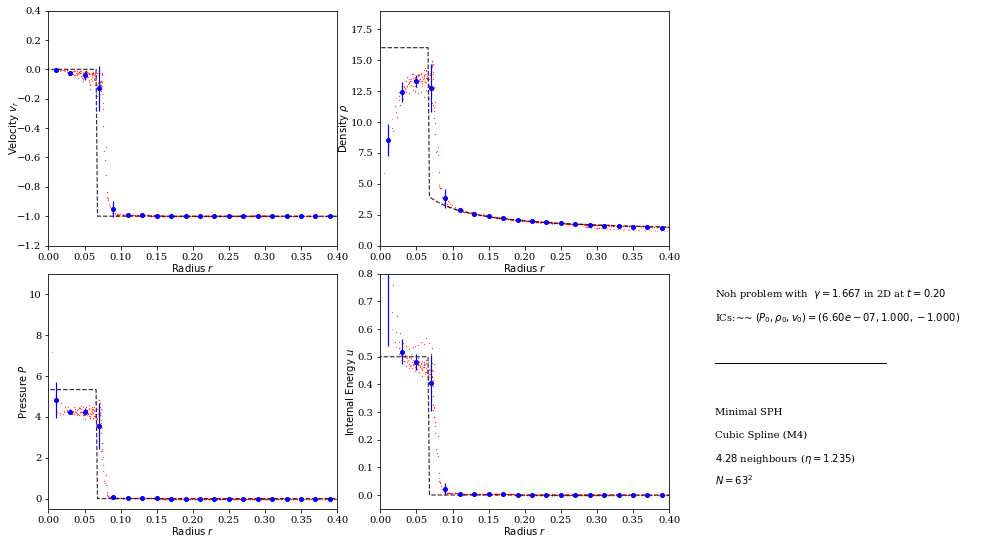

In [145]:
# Plot the interesting quantities
fig = plt.figure(figsize=(14, 8)) 

# Velocity profile --------------------------------
plt.subplot(231)
plt.plot(r, v, ".", color="r", ms=0.5, alpha=0.2)
plt.plot(x_s, v_s, "--", color="k", alpha=0.8, lw=1.2)
plt.errorbar(r_bin, v_bin, yerr=v_sigma_bin, fmt=".", ms=8.0, color="b", lw=1.2)
plt.xlabel("${\\rm{Radius}}~r$", labelpad=0)
plt.ylabel("${\\rm{Velocity}}~v_r$", labelpad=-4)
plt.xlim(0, 0.4)
plt.ylim(-1.2, 0.4)

# Density profile --------------------------------
plt.subplot(232)
plt.plot(r, rho, ".", color="r", ms=0.5, alpha=0.2)
plt.plot(x_s, rho_s, "--", color="k", alpha=0.8, lw=1.2)
plt.errorbar(r_bin, rho_bin, yerr=rho_sigma_bin, fmt=".", ms=8.0, color="b", lw=1.2)
plt.xlabel("${\\rm{Radius}}~r$", labelpad=0)
plt.ylabel("${\\rm{Density}}~\\rho$", labelpad=0)
plt.xlim(0, 0.4)
plt.ylim(0, 19)

# Pressure profile --------------------------------
plt.subplot(234)
plt.plot(r, P, ".", color="r", ms=0.5, alpha=0.2)
plt.plot(x_s, P_s, "--", color="k", alpha=0.8, lw=1.2)
plt.errorbar(r_bin, P_bin, yerr=P_sigma_bin, fmt=".", ms=8.0, color="b", lw=1.2)
plt.xlabel("${\\rm{Radius}}~r$", labelpad=0)
plt.ylabel("${\\rm{Pressure}}~P$", labelpad=0)
plt.xlim(0, 0.4)
plt.ylim(-0.5, 11)

# Internal energy profile -------------------------
plt.subplot(235)
plt.plot(r, u, ".", color="r", ms=0.5, alpha=0.2)
plt.plot(x_s, u_s, "--", color="k", alpha=0.8, lw=1.2)
plt.errorbar(r_bin, u_bin, yerr=u_sigma_bin, fmt=".", ms=8.0, color="b", lw=1.2)
plt.xlabel("${\\rm{Radius}}~r$", labelpad=0)
plt.ylabel("${\\rm{Internal~Energy}}~u$", labelpad=0)
plt.xlim(0, 0.4)
plt.ylim(-0.05, 0.8)

# Information -------------------------------------
plt.subplot(236, frameon=False)

plt.text(
    -0.49,
    0.9,
    "Noh problem with  $\\gamma=%.3f$ in 2D at $t=%.2f$" % (gas_gamma, time),
    fontsize=10,
)
plt.text(
    -0.49,
    0.8,
    "ICs:~~ $(P_0, \\rho_0, v_0) = (%1.2e, %.3f, %.3f)$" % (P0, rho0, -v0),
    fontsize=10,
)

plt.plot([-0.49, 0.1], [0.62, 0.62], "k-", lw=1)
#plt.text(-0.49, 0.5, "$\\textsc{Peano}$ %s" % git, fontsize=10)
plt.text(-0.49, 0.4, scheme, fontsize=10)
plt.text(-0.49, 0.3, kernel, fontsize=10)
plt.text(-0.49, 0.2, "$%.2f$ neighbours ($\\eta=%.3f$)" % (neighbours, eta), fontsize=10)
plt.text(-0.49, 0.1, "$N=%.0i^2$" % (N_parts), fontsize=10)
plt.xlim(-0.5, 0.5)
plt.ylim(0, 1)
plt.xticks([])
plt.yticks([])

plt.show()
plt.close()